## Data Exploration

In [31]:
%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [32]:
# import libraries

import mikeio
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import modelskill as ms
import torch

# dataset helper
from helper import get_altimetry_obs, get_u_v_point_obs, get_wl_point_obs
from helper import plot_shred_reconstruction

# suppress warnings
import contextlib
import io


In [33]:
# folders
dfs_fldr = "datasets/output/Area.dfsu"
msh_fldr = "datasets/input/Mesh_8000_elems_HD_v2.mesh"
obs_fldr  = "datasets/observations/"

msh = mikeio.open(msh_fldr)
dfs = mikeio.open(dfs_fldr)

In [34]:
# get data

print("dfs:", dfs)
print("\nmesh:", msh)

dfs: <mikeio.Dfsu2DH>
number of elements: 8566
number of nodes: 4504
projection: LONG/LAT
items:
  0:  Surface elevation <Surface Elevation> (meter)
  1:  U velocity <u velocity component> (meter per sec)
  2:  V velocity <v velocity component> (meter per sec)
time: 2022-01-01 00:00:00 - 2023-12-31 23:00:00 (35039 records)

mesh: <Mesh>
number of nodes: 4504
number of elements: 8566
projection: LONG/LAT


## Simulations

In [ ]:
# get covered area

geom = msh.geometry
covered_area = geom.get_element_area().sum()/1e6
print("Covered area (km^2):", covered_area)

Covered area (km^2): 236124.18973899263


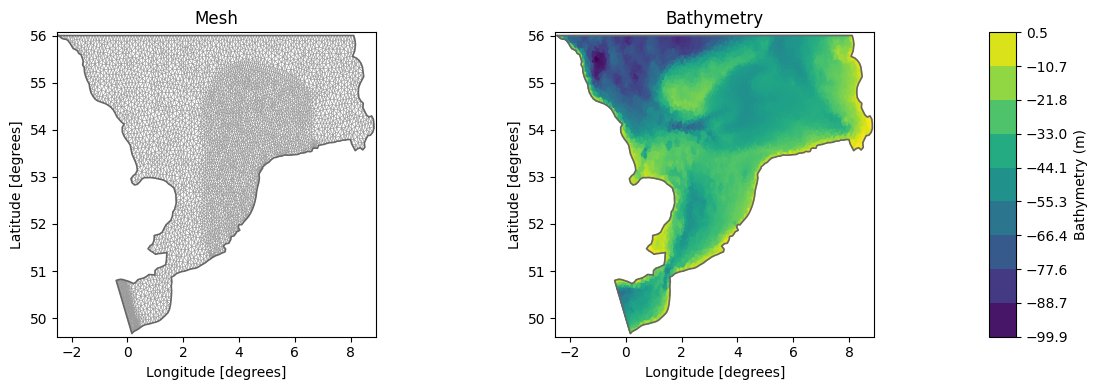

In [ ]:
# plot mesh and geometry

fig, axs = plt.subplots(1, 2, figsize=(12, 4))
geom.plot.mesh(ax=axs[0])
geom.plot(ax=axs[1])
plt.tight_layout()
plt.show()

In [ ]:
# read data with time slice

ds = dfs.read(time = slice("2022-01-03", "2023-12-31"))

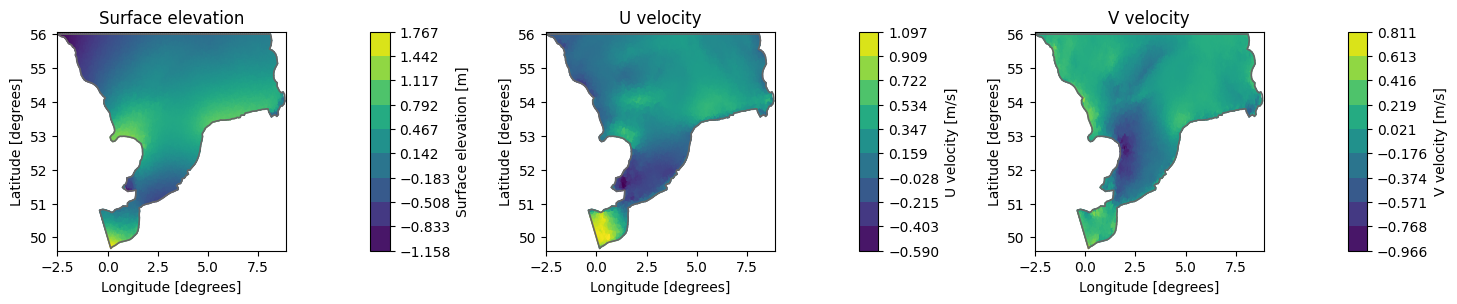

In [ ]:
# plot surface elevation and velocities at the last time step

plot_time = ds.time[-1]
fig,axs = plt.subplots(1, 3, figsize=(15,5))
ds["Surface elevation"].sel(time=plot_time).plot(ax=axs[0], title="Surface elevation")
ds["U velocity"].sel(time=plot_time).plot(ax=axs[1], title="U velocity")
ds["V velocity"].sel(time=plot_time).plot(ax=axs[2], title="V velocity")
plt.tight_layout()
plt.show()

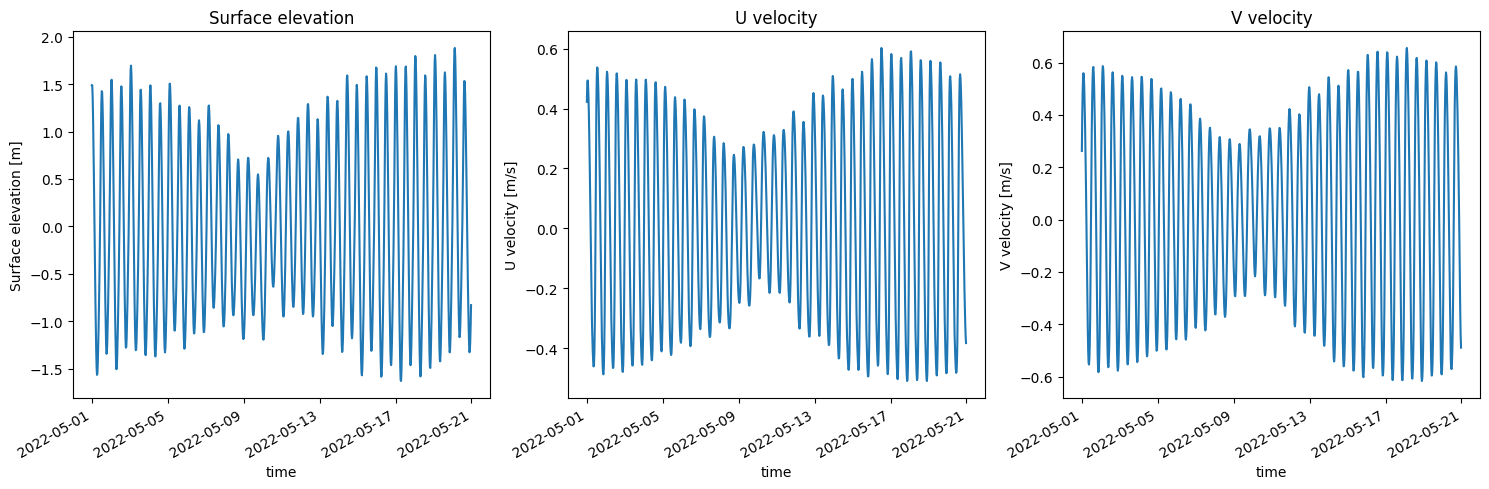

In [ ]:
# Select a point (x,y) and a time interval, then plot the surface elevation and velocities at that point over time.

p = (2.5, 51.5)
time_interval=slice("2022-05-01","2022-05-20") if "2022-05-01" in ds.time else ds.time[:100]

fig,axs = plt.subplots(1,3, figsize=(15,5))
ds["Surface elevation"].sel(x=p[0],y=p[1],time=time_interval).plot(ax=axs[0],title="Surface elevation")
ds["U velocity"].sel(x=p[0],y=p[1],time=time_interval).plot(ax=axs[1],title="U velocity")
ds["V velocity"].sel(x=p[0],y=p[1],time=time_interval).plot(ax=axs[2],title="V velocity")
plt.tight_layout()
plt.show()

## Water Level Sensors

<div>
<style scoped>
    .dataframe tbody tr th:only-of-type {
        vertical-align: middle;
    }

    .dataframe tbody tr th {
        vertical-align: top;
    }

    .dataframe thead th {
        text-align: right;
    }
</style>
<table border="1" class="dataframe">
  <thead>
    <tr style="text-align: right;">
      <th>observation</th>
      <th>n</th>
      <th>bias</th>
      <th>rmse</th>
      <th>urmse</th>
      <th>mae</th>
      <th>cc</th>
      <th>si</th>
      <th>r2</th>
    </tr>
  </thead>
  <tbody>
    <tr>
      <th>Dover</th>
      <td>16976</td>
      <td>-0.0</td>
      <td>0.438</td>
      <td>0.438</td>
      <td>0.149</td>
      <td>0.968</td>
      <td>0.291</td>
      <td>0.934</td>
    </tr>
    <tr>
      <th>ZeebruggeWielingendok</th>
      <td>209653</td>
      <td>-0.0</td>
      <td>0.337</td>
      <td>0.337</td>
      <td>0.296</td>
      <td>0.986</td>
      <td>0.303</td>
      <td>0.929</td>
    </tr>
    <tr>
      <th>Westkapelle</th>
      <td>104827</td>
      <td>0.0</td>
      <td>0.325</td>
      <td>0.325</td>
      <td>0.274</td>
      <td>0.977</td>
      <td>0.315</td>
      <td>0.924</td>
    </tr>
    <tr>
      <th>NWA</th>
      <td>79352</td>
      <td>-0.0</td>
      <td>0.143</td>
      <td>0.143</td>
      <td>0.114</td>
      <td>0.960</td>
      <td>0.350</td>
      <td>0.915</td>
    </tr>
    <tr>
      <th>Helgoland</th>
      <td>104827</td>
      <td>0.0</td>
      <td>0.259</td>
      <td>0.259</td>
      <td>0.221</td>
      <td>0.958</td>
      <td>0.344</td>
      <td>0.912</td>
    </tr>
    <tr>
      <th>K141</th>
      <td>104629</td>
      <td>-0.0</td>
      <td>0.142</td>
      <td>0.142</td>
      <td>0.108</td>
      <td>0.958</td>
      <td>0.364</td>
      <td>0.911</td>
    </tr>
    <tr>
      <th>Q11</th>
      <td>47436</td>
      <td>0.0</td>
      <td>0.146</td>
      <td>0.146</td>
      <td>0.101</td>
      <td>0.954</td>
      <td>0.368</td>
      <td>0.907</td>
    </tr>
    <tr>
      <th>J61</th>
      <td>104827</td>
      <td>-0.0</td>
      <td>0.171</td>
      <td>0.171</td>
      <td>0.126</td>
      <td>0.956</td>
      <td>0.363</td>
      <td>0.906</td>
    </tr>
    <tr>
      <th>Cromer</th>
      <td>16671</td>
      <td>-0.0</td>
      <td>0.386</td>
      <td>0.386</td>
      <td>0.255</td>
      <td>0.959</td>
      <td>0.366</td>
      <td>0.899</td>
    </tr>
    <tr>
      <th>L91</th>
      <td>104827</td>
      <td>-0.0</td>
      <td>0.191</td>
      <td>0.191</td>
      <td>0.146</td>
      <td>0.948</td>
      <td>0.387</td>
      <td>0.894</td>
    </tr>
    <tr>
      <th>Europlatform</th>
      <td>103533</td>
      <td>-0.0</td>
      <td>0.201</td>
      <td>0.201</td>
      <td>0.142</td>
      <td>0.944</td>
      <td>0.394</td>
      <td>0.887</td>
    </tr>
    <tr>
      <th>K13a</th>
      <td>101374</td>
      <td>-0.0</td>
      <td>0.156</td>
      <td>0.156</td>
      <td>0.120</td>
      <td>0.941</td>
      <td>0.416</td>
      <td>0.883</td>
    </tr>
    <tr>
      <th>DDW1A</th>
      <td>29713</td>
      <td>-0.0</td>
      <td>0.144</td>
      <td>0.144</td>
      <td>0.101</td>
      <td>0.936</td>
      <td>0.426</td>
      <td>0.875</td>
    </tr>
    <tr>
      <th>Lowestoft</th>
      <td>16940</td>
      <td>-0.0</td>
      <td>0.231</td>
      <td>0.231</td>
      <td>0.150</td>
      <td>0.928</td>
      <td>0.466</td>
      <td>0.847</td>
    </tr>
    <tr>
      <th>IJVA</th>
      <td>80117</td>
      <td>0.0</td>
      <td>0.140</td>
      <td>0.140</td>
      <td>0.111</td>
      <td>0.918</td>
      <td>0.488</td>
      <td>0.841</td>
    </tr>
    <tr>
      <th>F3platform</th>
      <td>104773</td>
      <td>0.0</td>
      <td>0.133</td>
      <td>0.133</td>
      <td>0.108</td>
      <td>0.862</td>
      <td>0.662</td>
      <td>0.718</td>
    </tr>
  </tbody>
</table>
</div>

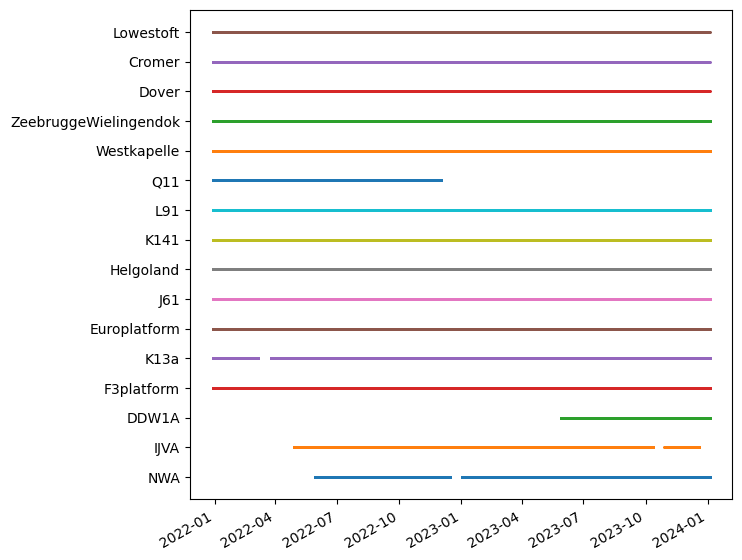

In [52]:
# plot temporal coverage of observations

wllist = get_wl_point_obs()
ms.plotting.temporal_coverage(wllist)
plt.show()

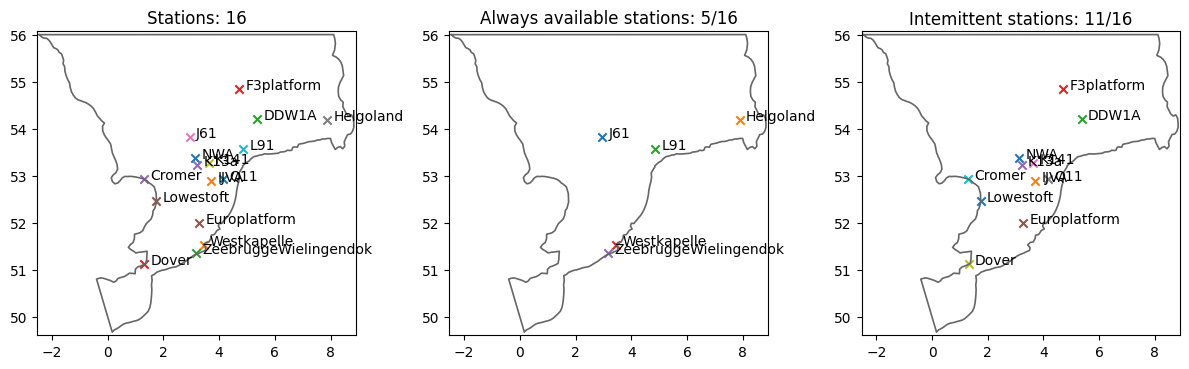

In [ ]:
# Select stations with full temporal coverage and plot their spatial distribution, along with the intermittent stations.

stations = []
availables = []
intermittent = []
for i in range(len(wllist)):
    stations.append(wllist[i])
    if ds.time.isin(wllist[i].time).all():
        availables.append(wllist[i])
    else:
        intermittent.append(wllist[i])

fig, axs = plt.subplots(1,3, figsize = (12,4))
ms.plotting.spatial_overview(stations, mod = msh.geometry, figsize = (5,5), ax=axs[0], title=f"Stations: {len(stations)}")
ms.plotting.spatial_overview(availables, mod = msh.geometry, figsize = (5,5), ax=axs[1], title=f"Always available stations: {len(availables)}/{len(stations)}")
ms.plotting.spatial_overview(intermittent, mod = msh.geometry, figsize = (5,5), ax=axs[2], title=f"Intemittent stations: {len(intermittent)}/{len(stations)}")

plt.tight_layout()
plt.show()


In [ ]:
# skill assessment of the model against the observations

with contextlib.redirect_stderr(io.StringIO()):
    mr = ms.DfsuModelResult(mikeio.read(dfs_fldr,time=slice("2022-01-03","2023-12-31"))[0], name="MIKE21")
    cmps = []
    for o in wllist:
        cmp = ms.match(obs=o, mod=mr)
        cmps.append(cmp.remove_bias())
    cc = ms.ComparerCollection(cmps)
    display(cc.skill().sort_values("r2", ascending=False).round(3))

    del mr, cmps

,n,bias,rmse,urmse,mae,cc,si,r2
observation,,,,,,,,
Dover,16976,-0.0,0.438,0.438,0.149,0.968,0.291,0.934
ZeebruggeWielingendok,209653,-0.0,0.337,0.337,0.296,0.986,0.303,0.929
Westkapelle,104827,0.0,0.325,0.325,0.274,0.977,0.315,0.924
NWA,79352,-0.0,0.143,0.143,0.114,0.960,0.350,0.915
Helgoland,104827,0.0,0.259,0.259,0.221,0.958,0.344,0.912
K141,104629,-0.0,0.142,0.142,0.108,0.958,0.364,0.911
Q11,47436,0.0,0.146,0.146,0.101,0.954,0.368,0.907
J61,104827,-0.0,0.171,0.171,0.126,0.956,0.363,0.906
Cromer,16671,-0.0,0.386,0.386,0.255,0.959,0.366,0.899


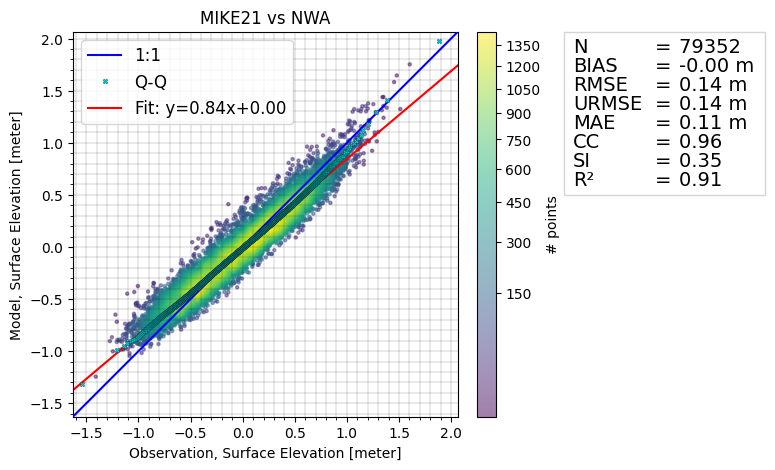

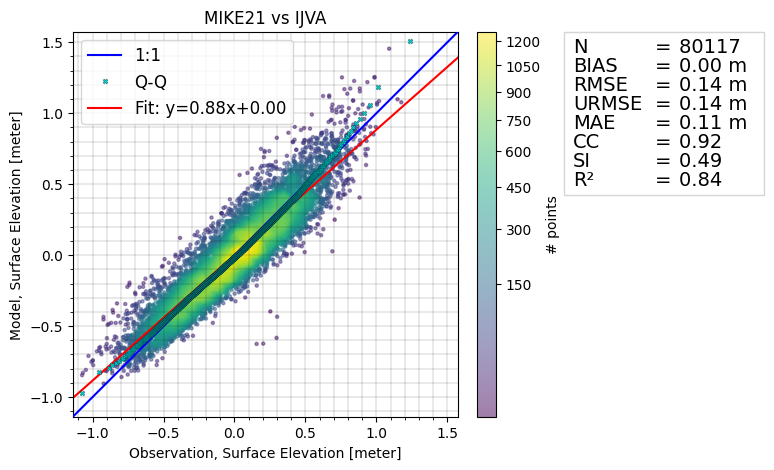

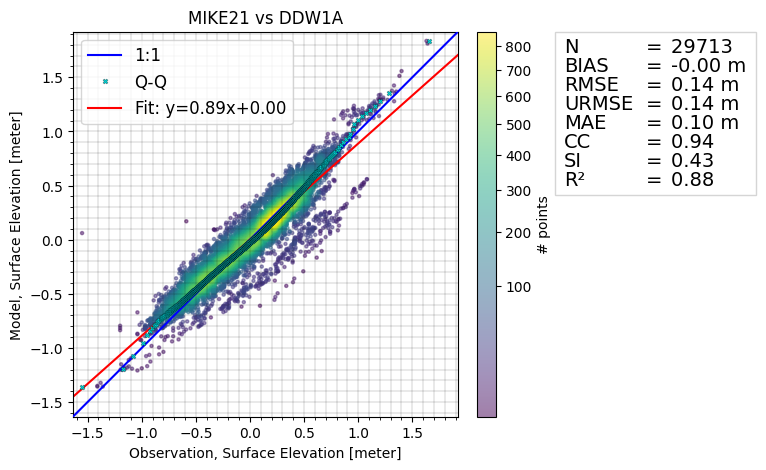

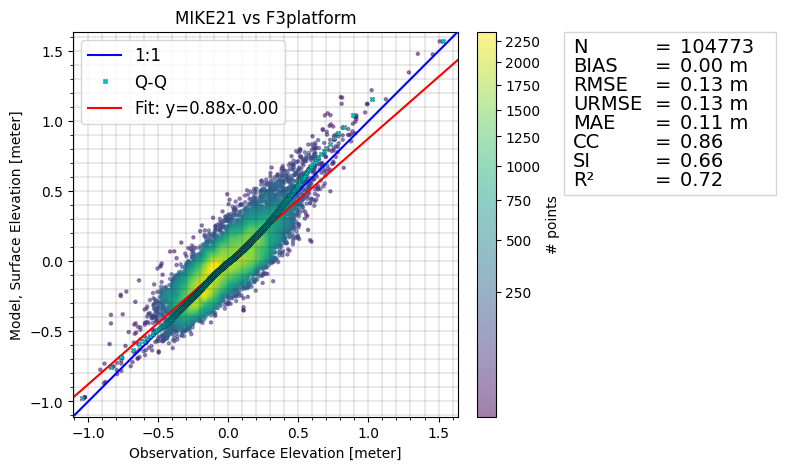

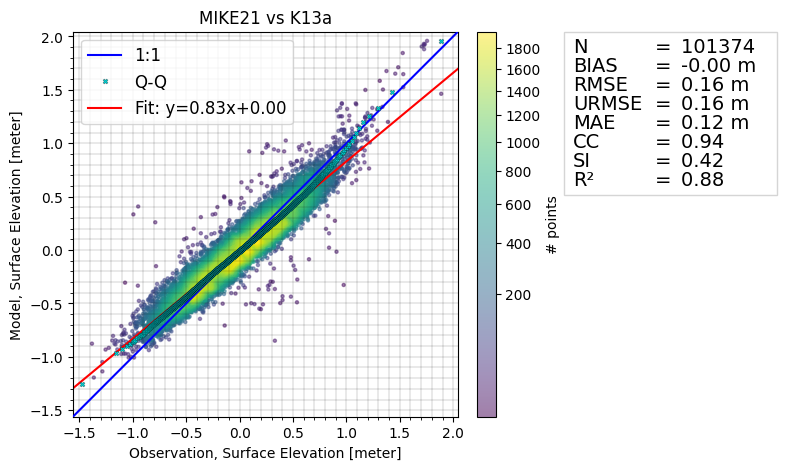

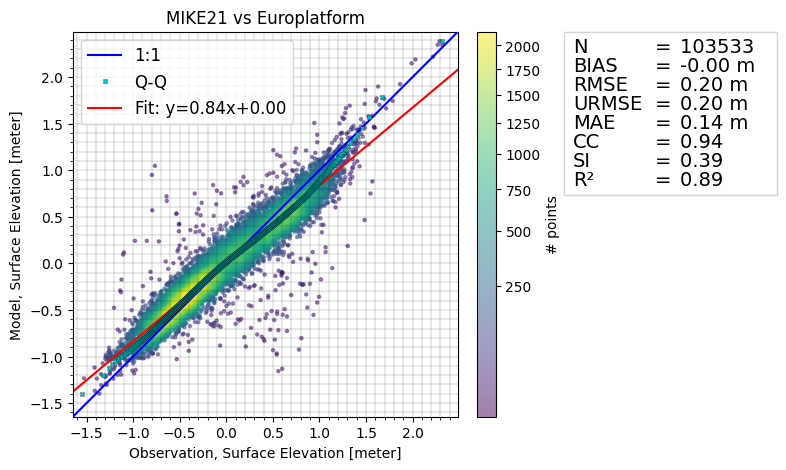

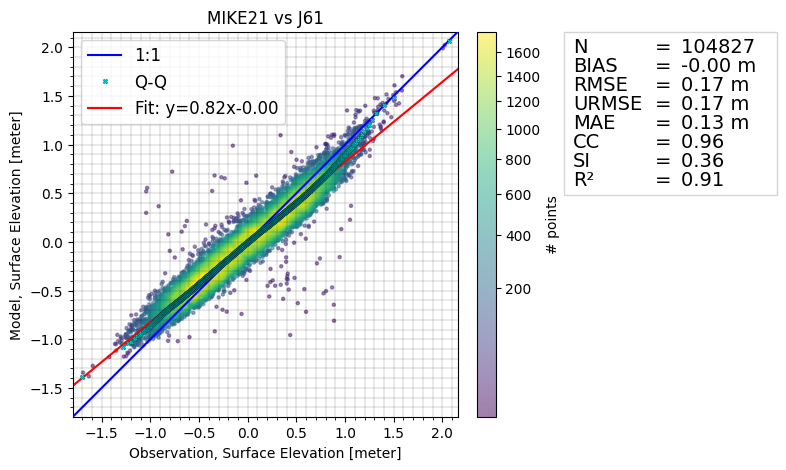

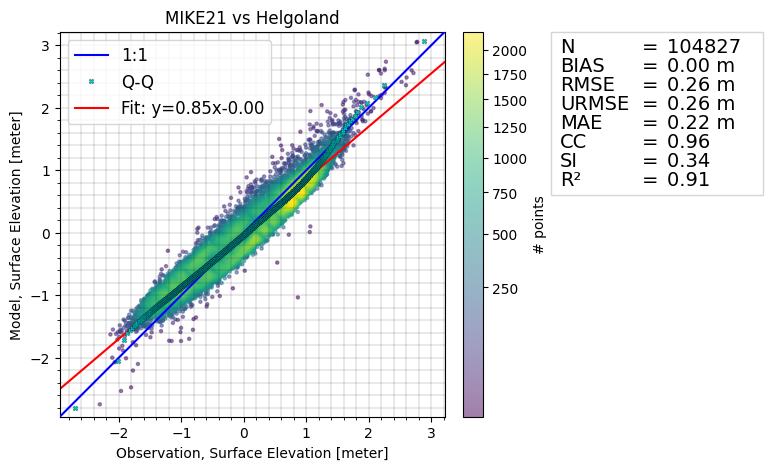

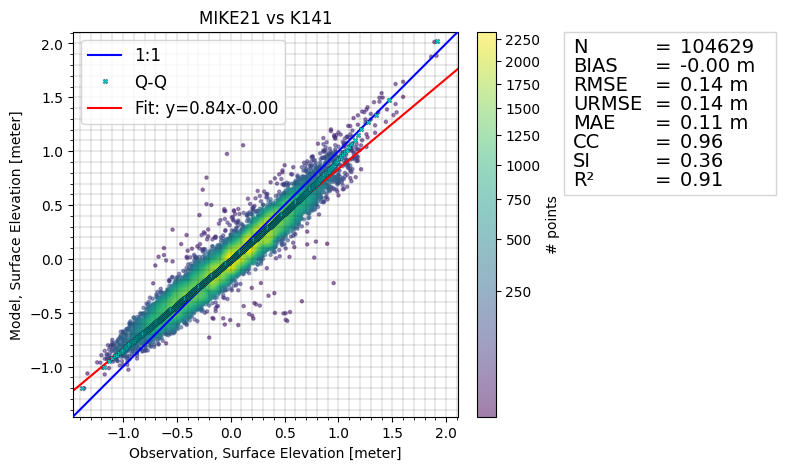

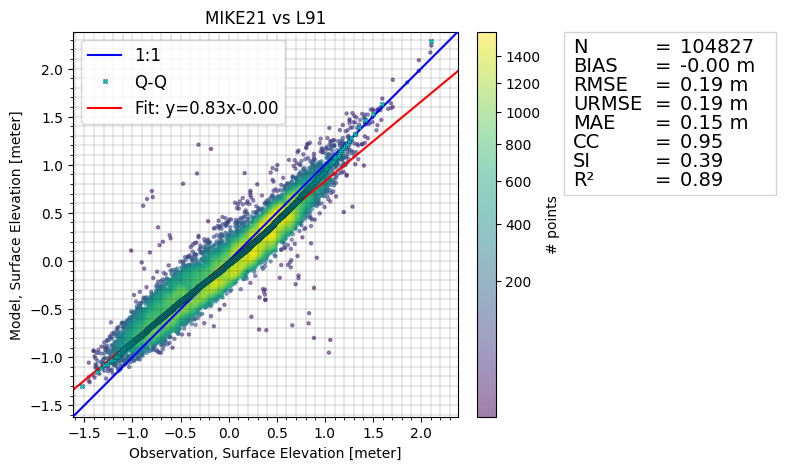

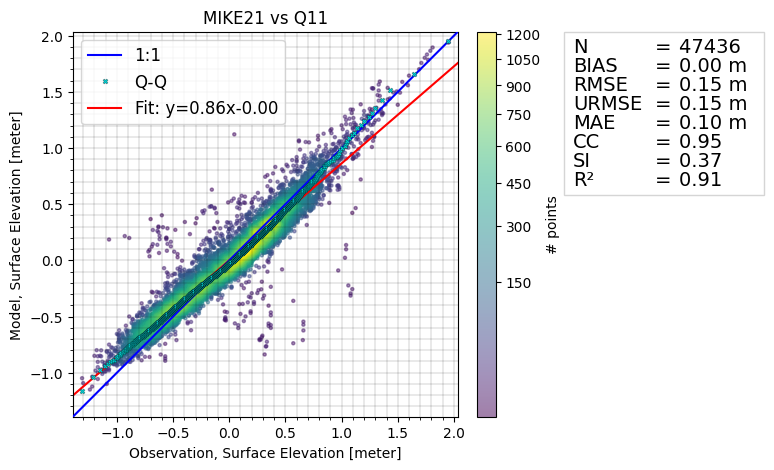

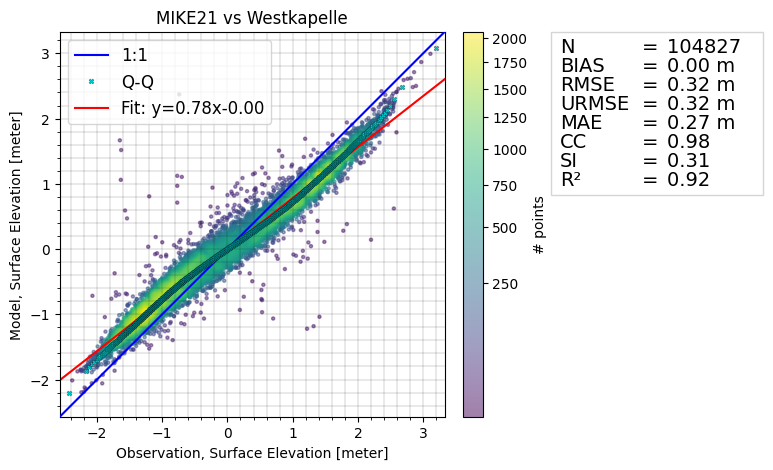

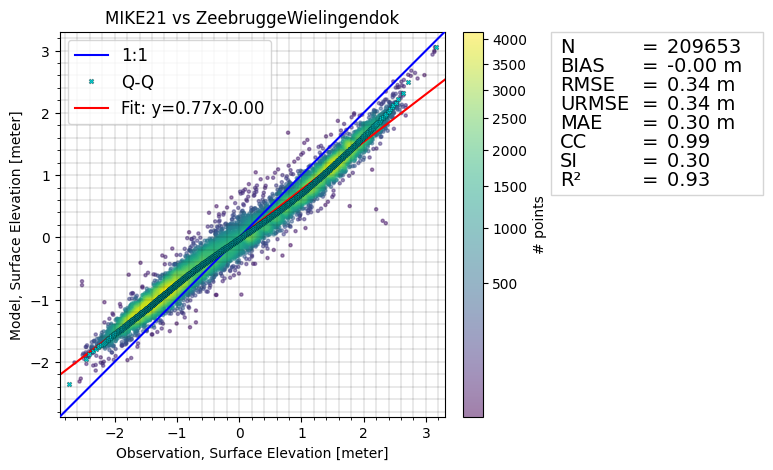

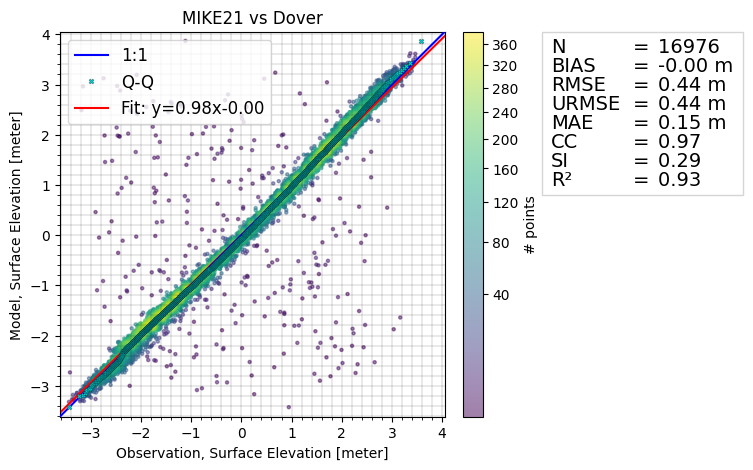

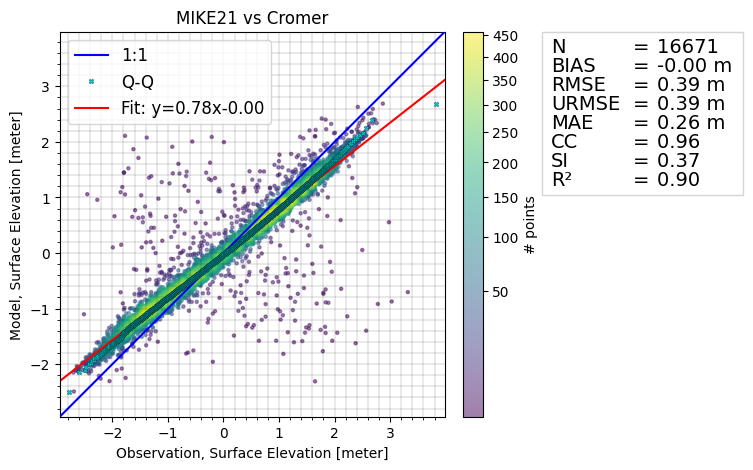

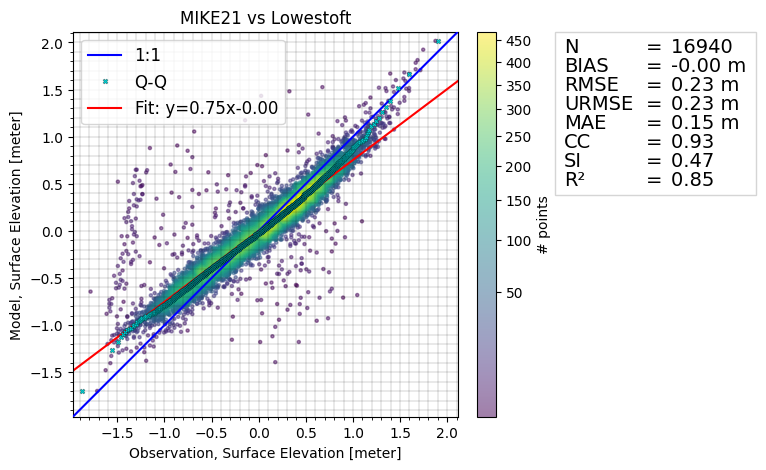

In [ ]:
# plot skill metrics

n_points_shown = 10000
for cmp in cc:
    cmp.plot.scatter(skill_table=True, show_points=n_points_shown, figsize=(6,5), bins=40);

## Current Stations

<div>
<style scoped>
    .dataframe tbody tr th:only-of-type {
        vertical-align: middle;
    }

    .dataframe tbody tr th {
        vertical-align: top;
    }

    .dataframe thead th {
        text-align: right;
    }
</style>
<table border="1" class="dataframe">
  <thead>
    <tr style="text-align: right;">
      <th>observations</th>
      <th>n</th>
      <th>bias</th>
      <th>rmse</th>
      <th>urmse</th>
      <th>mae</th>
      <th>cc</th>
      <th>si</th>
      <th>r2</th>
    </tr>
  </thead>
  <tbody>
    <tr>
      <th>MO_NN</th>
      <td>82304</td>
      <td>-0.0</td>
      <td>0.401</td>
      <td>0.401</td>
      <td>0.321</td>
      <td>0.744</td>
      <td>1.278</td>
      <td>-0.282</td>
    </tr>
  </tbody>
</table>
</div>

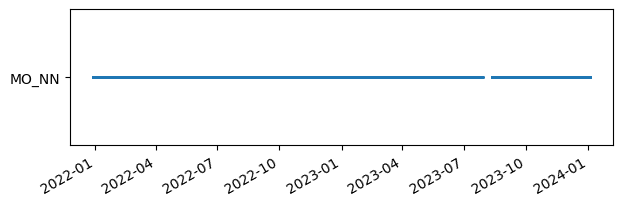

In [ ]:
# plot temporal coverage of velocity observations

ulist, vlist = get_u_v_point_obs()  
ms.plotting.temporal_coverage(ulist)
plt.show()

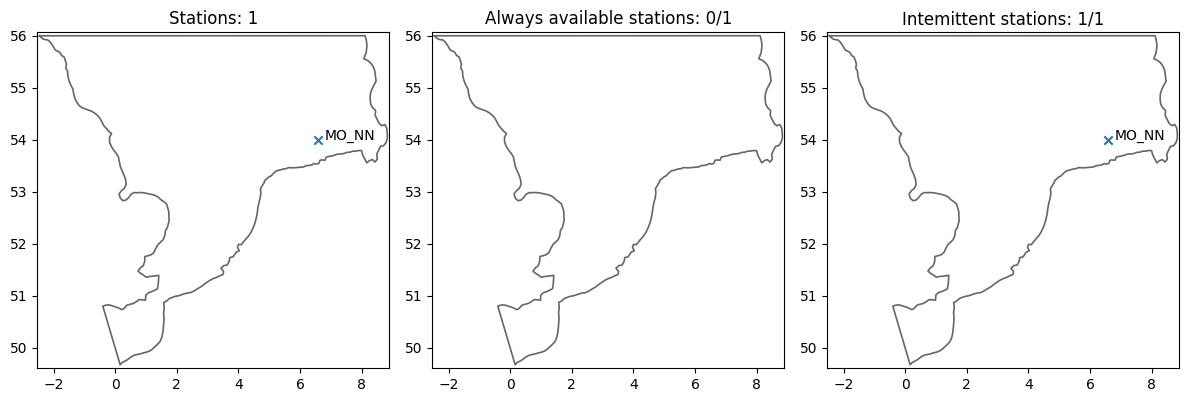

In [ ]:
# Select stations with full temporal coverage and plot their spatial distribution, along with the intermittent stations.

stations = []
availables = []
intermittent = []
for i in range(len(ulist)):
    stations.append(ulist[i])
    if ds.time.isin(ulist[i].time).all():
        availables.append(ulist[i])
    else:
        intermittent.append(ulist[i])

fig, axs = plt.subplots(1,3, figsize = (12,4))
ms.plotting.spatial_overview(stations, mod = msh.geometry, figsize = (5,5), ax=axs[0], title=f"Stations: {len(stations)}")
ms.plotting.spatial_overview(availables, mod = msh.geometry, figsize = (5,5), ax=axs[1], title=f"Always available stations: {len(availables)}/{len(stations)}")
ms.plotting.spatial_overview(intermittent, mod = msh.geometry, figsize = (5,5), ax=axs[2], title=f"Intemittent stations: {len(intermittent)}/{len(stations)}")

plt.tight_layout()
plt.show()


In [ ]:
# skill assessment of the model against the observations

with contextlib.redirect_stderr(io.StringIO()):
    mr = ms.DfsuModelResult(mikeio.read(dfs_fldr,time=slice("2022-01-03","2023-12-31"))[0], name="MIKE21")
    cmps = []
    for o in ulist:
        cmp = ms.match(obs=o, mod=mr)
        cmps.append(cmp.remove_bias())
    cc_u = ms.ComparerCollection(cmps)
    display(cc_u.skill().sort_values("r2", ascending=False).round(3))

    del mr, cmps

with contextlib.redirect_stderr(io.StringIO()):
    mr = ms.DfsuModelResult(mikeio.read(dfs_fldr,time=slice("2022-01-03","2023-12-31"))[0], name="MIKE21")
    cmps = []
    for o in ulist:
        cmp = ms.match(obs=o, mod=mr)
        cmps.append(cmp.remove_bias())
    cc_v = ms.ComparerCollection(cmps)
    display(cc_v.skill().sort_values("r2", ascending=False).round(3))

    del mr, cmps

,n,bias,rmse,urmse,mae,cc,si,r2
observation,,,,,,,,
MO_NN,82304,-0.0,0.401,0.401,0.321,0.744,1.278,-0.282


,n,bias,rmse,urmse,mae,cc,si,r2
observation,,,,,,,,
MO_NN,82304,-0.0,0.401,0.401,0.321,0.744,1.278,-0.282


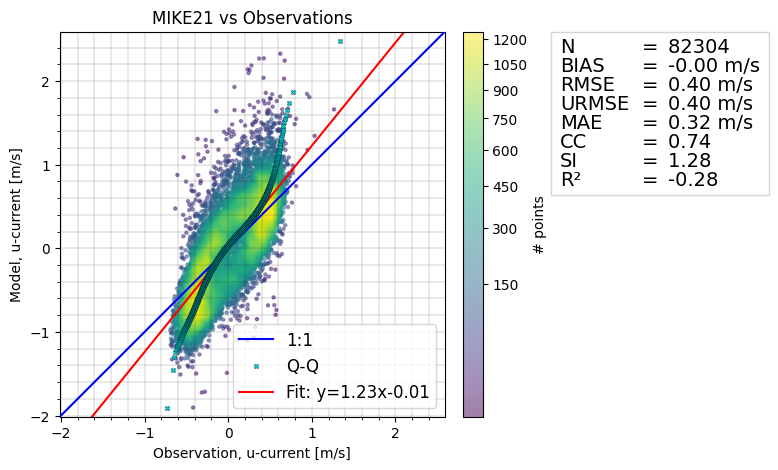

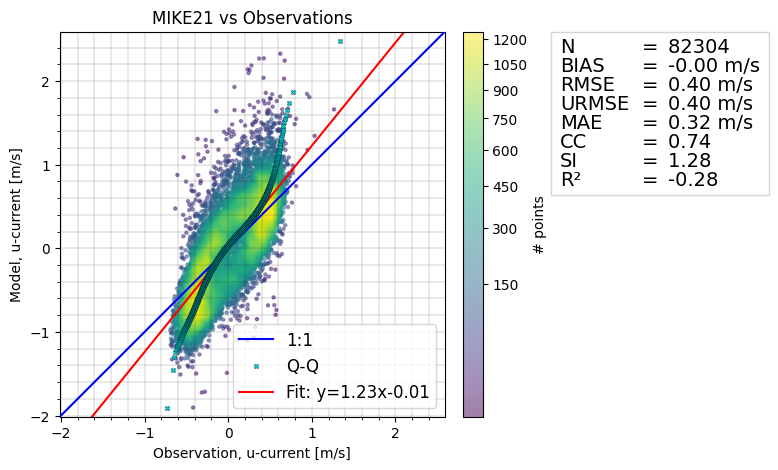

In [ ]:
# plot skill metrics

cc_u.plot.scatter(skill_table=True, show_points=n_points_shown, figsize=(6,5), bins=40);
cc_v.plot.scatter(skill_table=True, show_points=n_points_shown, figsize=(6,5), bins=40);

## Altimetry Stations

<div>
<style scoped>
    .dataframe tbody tr th:only-of-type {
        vertical-align: middle;
    }

    .dataframe tbody tr th {
        vertical-align: top;
    }

    .dataframe thead th {
        text-align: right;
    }
</style>
<table border="1" class="dataframe">
  <thead>
    <tr style="text-align: right;">
      <th></th>
      <th>n</th>
      <th>bias</th>
      <th>rmse</th>
      <th>urmse</th>
      <th>mae</th>
      <th>cc</th>
      <th>si</th>
      <th>r2</th>
    </tr>
    <tr>
      <th>observation</th>
      <th></th>
      <th></th>
      <th></th>
      <th></th>
      <th></th>
      <th></th>
      <th></th>
      <th></th>
    </tr>
  </thead>
  <tbody>
    <tr>
      <th>6a</th>
      <td>38924</td>
      <td>-0.0</td>
      <td>0.135</td>
      <td>0.135</td>
      <td>0.102</td>
      <td>0.986</td>
      <td>0.232</td>
      <td>0.970</td>
    </tr>
    <tr>
      <th>c2</th>
      <td>31110</td>
      <td>-0.0</td>
      <td>0.150</td>
      <td>0.150</td>
      <td>0.112</td>
      <td>0.985</td>
      <td>0.244</td>
      <td>0.967</td>
    </tr>
    <tr>
      <th>sa</th>
      <td>27372</td>
      <td>0.0</td>
      <td>0.153</td>
      <td>0.153</td>
      <td>0.110</td>
      <td>0.985</td>
      <td>0.248</td>
      <td>0.966</td>
    </tr>
    <tr>
      <th>j3</th>
      <td>35177</td>
      <td>-0.0</td>
      <td>0.135</td>
      <td>0.135</td>
      <td>0.103</td>
      <td>0.985</td>
      <td>0.244</td>
      <td>0.966</td>
    </tr>
    <tr>
      <th>3a</th>
      <td>29526</td>
      <td>0.0</td>
      <td>0.147</td>
      <td>0.147</td>
      <td>0.110</td>
      <td>0.985</td>
      <td>0.250</td>
      <td>0.965</td>
    </tr>
    <tr>
      <th>3b</th>
      <td>31282</td>
      <td>0.0</td>
      <td>0.165</td>
      <td>0.165</td>
      <td>0.113</td>
      <td>0.984</td>
      <td>0.264</td>
      <td>0.963</td>
    </tr>
  </tbody>
</table>
</div>

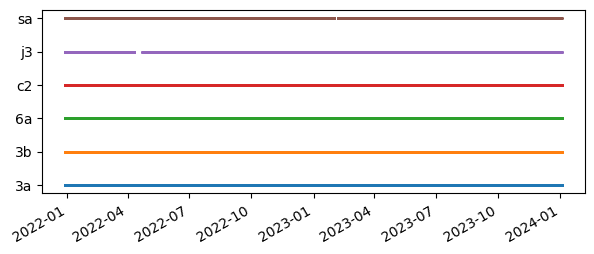

In [ ]:
# plot temporal coverage of altimetry observations

altlist = get_altimetry_obs()
ms.plotting.temporal_coverage(altlist)
plt.show()

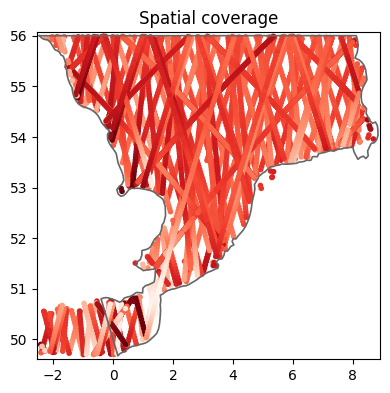

In [ ]:
# Select stations with full temporal coverage and plot their spatial distribution, along with the intermittent stations.

altlist_jan22 = [al.sel(time=slice("2022-01-01","2022-01-31")) for al in altlist]  
ms.plotting.spatial_overview(altlist_jan22, mod=msh.geometry,figsize=(4,4));
plt.tight_layout() 

In [ ]:
# skill assessment of the model against the observations

with contextlib.redirect_stderr(io.StringIO()):
    mr = ms.DfsuModelResult(mikeio.read(dfs_fldr,time=slice("2022-01-03","2023-12-31"))[0], name="MIKE21")
    cmps = []
    for o in altlist:
        cmp = ms.match(obs=o, mod=mr)
        cmps.append(cmp.remove_bias())
    cc = ms.ComparerCollection(cmps)
    display(cc.skill().sort_values("r2", ascending=False).round(3))

    del mr, cmps

,n,bias,rmse,urmse,mae,cc,si,r2
observation,,,,,,,,
6a,38924,-0.0,0.135,0.135,0.102,0.986,0.232,0.970
c2,31110,-0.0,0.150,0.150,0.112,0.985,0.244,0.967
sa,27372,0.0,0.153,0.153,0.110,0.985,0.248,0.966
j3,35177,-0.0,0.135,0.135,0.103,0.985,0.244,0.966
3a,29526,0.0,0.147,0.147,0.110,0.985,0.250,0.965
3b,31282,0.0,0.165,0.165,0.113,0.984,0.264,0.963


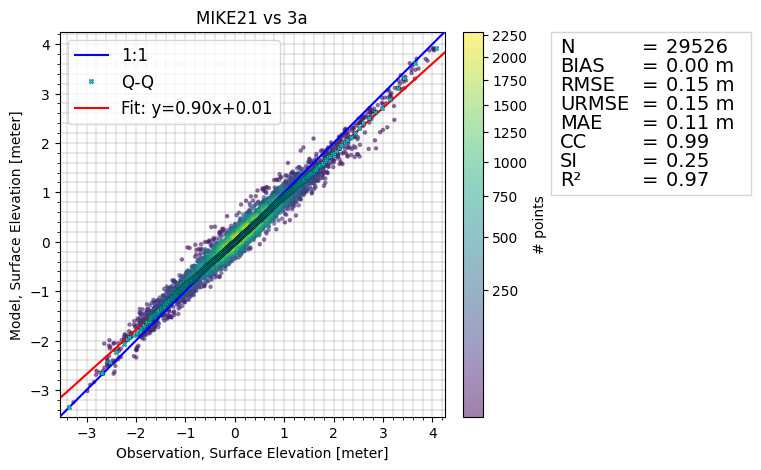

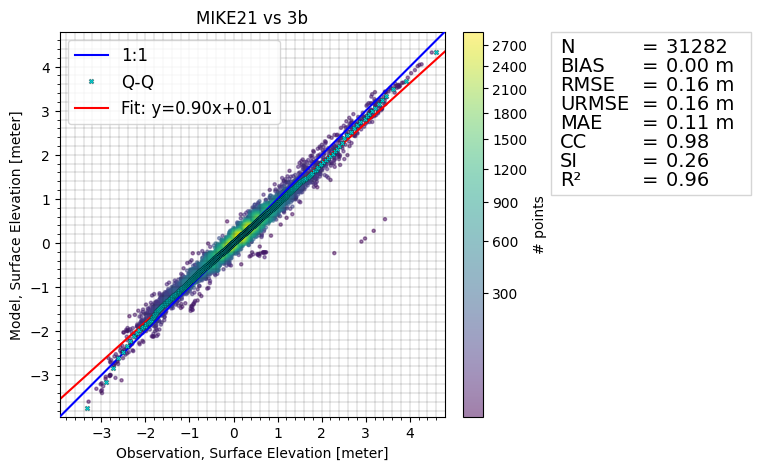

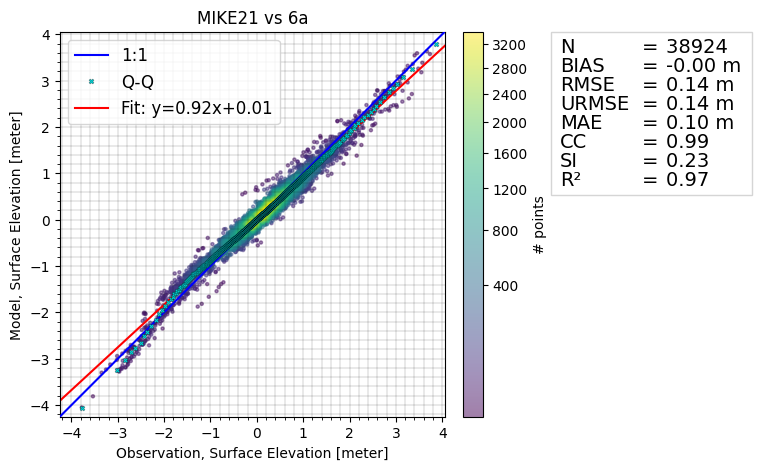

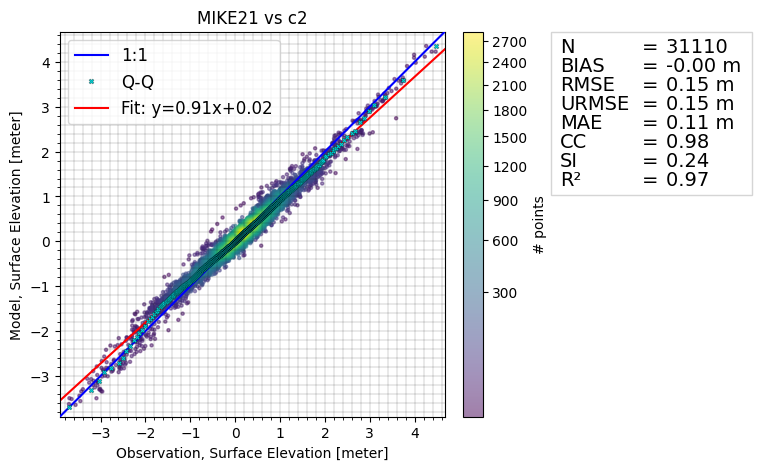

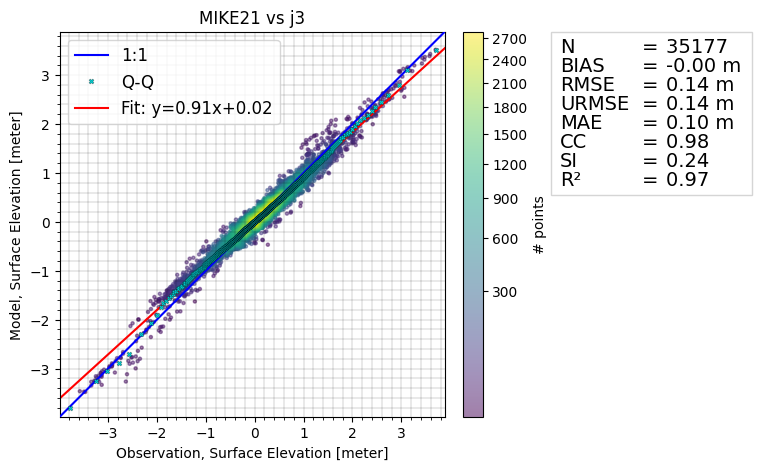

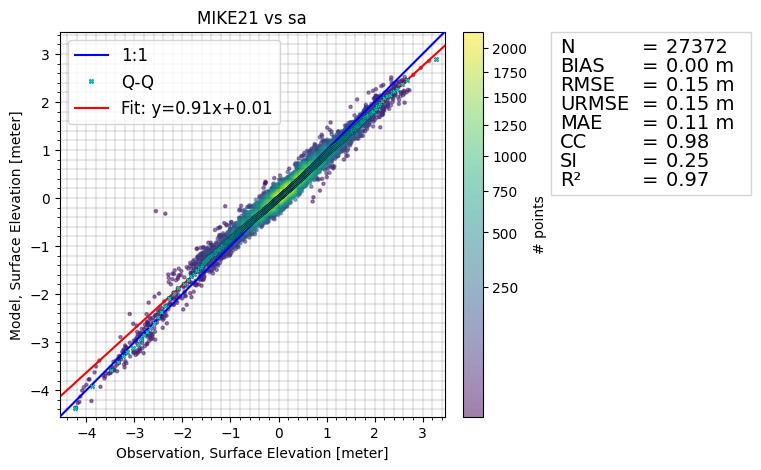

In [ ]:
# plot skill metrics

n_points_shown = 10000
for cmp in cc:
    cmp.plot.scatter(skill_table=True, show_points=n_points_shown, figsize=(6,5), bins=40);